<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%2011/MRayhanZamzami_JS11_P5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 5 - Klasifikasi Citra Siang dan Malam (Threshold vs SVM)

Dataset: Citra luar ruangan siang dan malam diekstraksi kecerahan rata-rata (HSV space).

## Langkah 0 - Import Library dan Definisi Direktori

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd

# Direktori citra (fallback cross-platform)
train_dir = 'dataset/images/training/' if Path('dataset/images/training/').exists() else 'images/training/'
test_dir = 'dataset/images/test/' if Path('dataset/images/test/').exists() else 'images/test/'
print('Train path:', train_dir)
print('Test path :', test_dir)

Train path: dataset/images/training/
Test path : dataset/images/test/


## Langkah 1 - Load Data dan Visualisasi

In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for d in p.glob('*'):
        if d.is_dir():
            label = d.name
            for img_path in d.glob('*.jpg'):
                img = cv2.imread(str(img_path))
                if img is not None:
                    # Konversi BGR ke RGB untuk visualisasi
                    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img_list.append((img_rgb, label))
    return img_list

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)
print(f'Total data latih: {len(train_img)}')
print(f'Total data uji  : {len(test_img)}')

Total data latih: 240
Total data uji  : 160


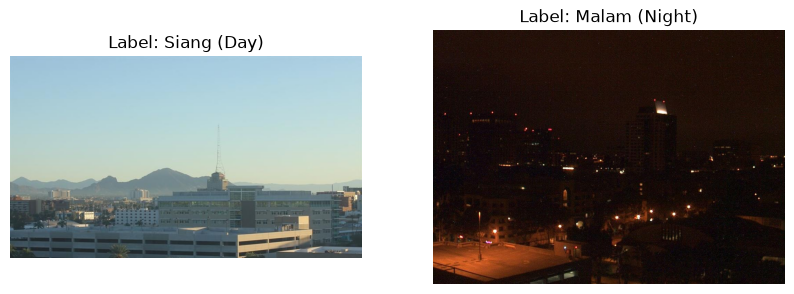

In [3]:
# Visualisasi sampel acak data latih
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
day_sample = next(img for img, lbl in train_img if lbl == 'day')
night_sample = next(img for img, lbl in train_img if lbl == 'night')

axes[0].imshow(day_sample)
axes[0].set_title('Label: Siang (Day)')
axes[0].axis('off')

axes[1].imshow(night_sample)
axes[1].set_title('Label: Malam (Night)')
axes[1].axis('off')
plt.show()

## Langkah 2 - Standarisasi Ukuran dan Encoding Label

In [4]:
def standardize_input(image):
    return cv2.resize(image, (550, 300))

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    return [(standardize_input(item[0]), label_encoder(item[1])) for item in img_list]

train_std = preprocess(train_img)
test_std = preprocess(test_img)
print('Standarisasi selesai. Dimensi citra:', train_std[0][0].shape)

Standarisasi selesai. Dimensi citra: (300, 550, 3)


## Langkah 3 - Ekstraksi Fitur Kecerahan (Kanal V pada HSV)

In [5]:
def avg_brightness(image_rgb):
    # Konversi ke HSV
    hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
    # Ambil kanal Value (brightness)
    v = hsv[:, :, 2]
    # Rata-rata nilai piksel
    return np.mean(v)

# Sampel kecerahan siang vs malam
print('Kecerahan rata-rata Siang:', avg_brightness(train_std[0][0]))
night_idx = next(i for i, item in enumerate(train_std) if item[1] == 0)
print('Kecerahan rata-rata Malam:', avg_brightness(train_std[night_idx][0]))

Kecerahan rata-rata Siang: 175.10869696969698
Kecerahan rata-rata Malam: 33.77705454545455


## Langkah 4 - Klasifikasi dengan Metode Thresholding

In [6]:
def predict_threshold(image_rgb, threshold=120):
    return 1 if avg_brightness(image_rgb) > threshold else 0

def evaluate_threshold(img_list, threshold=120):
    correct = sum(1 for img, lbl in img_list if predict_threshold(img, threshold) == lbl)
    return correct / len(img_list)

acc_train_thresh = evaluate_threshold(train_std, threshold=120)
acc_test_thresh = evaluate_threshold(test_std, threshold=120)
print(f'Akurasi Threshold Data Latih: {acc_train_thresh * 100:.2f}%')
print(f'Akurasi Threshold Data Uji  : {acc_test_thresh * 100:.2f}%')

Akurasi Threshold Data Latih: 84.17%
Akurasi Threshold Data Uji  : 86.88%


## Langkah 5 - Klasifikasi dengan Model SVM

In [7]:
# Buat DataFrame tabular dari fitur kecerahan
def extract_feature_df(img_list):
    data = [{'brightness': avg_brightness(img), 'label': lbl} for img, lbl in img_list]
    return pd.DataFrame(data)

df_train = extract_feature_df(train_std)
df_test = extract_feature_df(test_std)

X_train_svm = df_train[['brightness']].values
y_train_svm = df_train['label'].values
X_test_svm = df_test[['brightness']].values
y_test_svm = df_test['label'].values

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = SVC(kernel='rbf', C=10)
svm_model.fit(X_train_svm, y_train_svm)

train_acc_svm = accuracy_score(y_train_svm, svm_model.predict(X_train_svm))
test_acc_svm = accuracy_score(y_test_svm, svm_model.predict(X_test_svm))

print(f'Akurasi SVM Data Latih: {train_acc_svm * 100:.2f}%')
print(f'Akurasi SVM Data Uji  : {test_acc_svm * 100:.2f}%')
print('\nLaporan Klasifikasi SVM pada Data Uji:')
print(classification_report(y_test_svm, svm_model.predict(X_test_svm), target_names=['Night', 'Day']))

Akurasi SVM Data Latih: 88.33%
Akurasi SVM Data Uji  : 89.38%

Laporan Klasifikasi SVM pada Data Uji:
              precision    recall  f1-score   support

       Night       0.89      0.90      0.89        80
         Day       0.90      0.89      0.89        80

    accuracy                           0.89       160
   macro avg       0.89      0.89      0.89       160
weighted avg       0.89      0.89      0.89       160

